# Part 2: Python Tools

Covers Exploring Data with pandas through Building Models with scikit-learn. The [README](README.md) has the same content with the full table of contents; datasets and versions are listed in its Setup section.

In [1]:
# Shared setup: imports and paths used throughout. Run this cell first.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # keep TensorFlow's start-up logs quiet
from pathlib import Path
import logging, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="(Degrees of freedom|divide by zero|invalid value)")  # sparse correlations
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # Prophet's backend is chatty
logging.getLogger("tensorflow").setLevel(logging.ERROR)
DATA = Path("data")
IMAGES = Path("images")                                   # animations are written here
MODELS = Path("models")                                   # saved models
IMAGES.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
np.random.seed(42)                                        # for the classic np.random API
rng = np.random.default_rng(42)                           # for new code
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.0.5 | NumPy 2.5.3


<a id="4-exploring-data-with-pandas"></a>

## 4. Exploring Data with pandas

pandas is usually the first thing I import on a new dataset. It turns CSV files and database tables into DataFrames you can
explore, filter, clean and summarize in a few lines.

<a id="series-dataframes-and-csv-files"></a>

### Series, DataFrames and CSV Files

A **Series** is a one-dimensional labelled array (one column). A **DataFrame** is a table of Series that share an index.
You'll mostly create them by reading files with `pd.read_csv()` and write them back with `to_csv()`. Pass `index=False`
when exporting, or pandas writes the row labels as an extra unnamed column.

In [2]:
cars = pd.Series(["BMW", "Toyota", "Honda"])
colours = pd.Series(["Red", "Blue", "White"])
print(pd.DataFrame({"Car make": cars, "Colour": colours}), "\n")

car_sales = pd.read_csv(DATA / "car-sales.csv")
print(car_sales.head())

car_sales.to_csv("exported-car-sales.csv", index=False)   # index=False: don't write the row labels
print("\nRe-imported shape:", pd.read_csv("exported-car-sales.csv").shape)

  Car make Colour
0      BMW    Red
1   Toyota   Blue
2    Honda  White 

     Make Colour  Odometer (KM)  Doors       Price
0  Toyota  White         150043      4   $4,000.00
1   Honda    Red          87899      4   $5,000.00
2  Toyota   Blue          32549      3   $7,000.00
3     BMW  Black          11179      5  $22,000.00
4  Nissan  White         213095      4   $3,500.00

Re-imported shape: (10, 5)


<a id="describing-a-dataset"></a>

### Describing a Dataset

Start every analysis by looking at the shape and types of the data. **Attributes** describe the frame (`dtypes`,
`columns`, `index`, `shape`), while **methods** compute something (`describe()`, `info()`, `mean()`, `sum()`).

In the car-sales data, `Price` is text (`"$4,000.00"`), so it's missing from numeric summaries until it's converted.
Spotting that kind of problem early is the point of this step.

In [3]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
print(car_sales.dtypes, "\n")
print(car_sales.describe())
car_sales.info()
print("\nMean of numeric columns:\n", car_sales.mean(numeric_only=True))   # numeric_only required in pandas 2+

Make               str
Colour             str
Odometer (KM)    int64
Doors            int64
Price              str
dtype: object 

       Odometer (KM)      Doors
count      10.000000  10.000000
mean    78601.400000   4.000000
std     61983.471735   0.471405
min     11179.000000   3.000000
25%     35836.250000   4.000000
50%     57369.000000   4.000000
75%     96384.500000   4.000000
max    213095.000000   5.000000
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Make           10 non-null     str  
 1   Colour         10 non-null     str  
 2   Odometer (KM)  10 non-null     int64
 3   Doors          10 non-null     int64
 4   Price          10 non-null     str  
dtypes: int64(2), str(3)
memory usage: 532.0 bytes

Mean of numeric columns:
 Odometer (KM)    78601.4
Doors                4.0
dtype: float64


<a id="selecting-filtering-and-summarizing"></a>

### Selecting, Filtering and Summarizing

- `head(n)` and `tail(n)` show the first and last rows.
- `.loc[label]` selects by **index label**, while `.iloc[position]` selects by **integer position**. They look the same until
  the index stops being 0…n-1, for example after shuffling or filtering.
- Select a column with `df["Make"]`, and filter rows with a boolean condition: `df[df["Odometer (KM)"] > 100_000]`.
- Summarize with `pd.crosstab()` (frequency table of two columns), `groupby(...).mean()` and `value_counts()`.

loc[3] (label):
 3      dog
3    snake
dtype: str 
iloc[3] (position): panda 

     Make  Odometer (KM)
0  Toyota         150043
4  Nissan         213095 

Doors   3  4  5
Make           
BMW     0  0  1
Honda   0  3  0
Nissan  0  2  0
Toyota  1  3  0 

Make
BMW        11179.000000
Honda      62778.333333
Nissan    122347.500000
Toyota     85451.250000
Name: Odometer (KM), dtype: float64


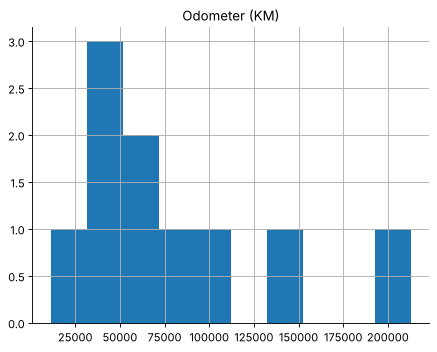

In [4]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
animals = pd.Series(["cat", "dog", "bird", "panda", "snake"], index=[0, 3, 9, 8, 3])
print("loc[3] (label):\n", animals.loc[3], "\niloc[3] (position):", animals.iloc[3], "\n")

print(car_sales[car_sales["Odometer (KM)"] > 100_000][["Make", "Odometer (KM)"]], "\n")
print(pd.crosstab(car_sales["Make"], car_sales["Doors"]), "\n")
print(car_sales.groupby("Make")["Odometer (KM)"].mean())

car_sales["Odometer (KM)"].hist(); plt.title("Odometer (KM)"); plt.show()

<a id="cleaning-text-columns"></a>

### Cleaning Text Columns

Prices stored as `"$4,000.00"` need the symbols stripped before they become numbers. String methods live under `.str`.

**Watch out:** a common snippet uses `.str.replace("[\$\,\.]", "")`. That also removes the decimal point, which multiplies
every price by 100. Keep the dot, pass `regex=True`, and convert with `pd.to_numeric`.

     Make    Price
0  Toyota   4000.0
1   Honda   5000.0
2  Toyota   7000.0
3     BMW  22000.0
4  Nissan   3500.0
Total sales: 76450.0


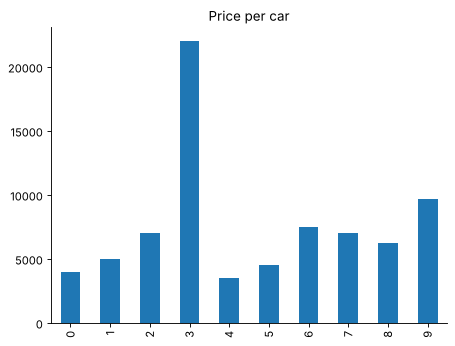

In [5]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))
print(car_sales[["Make", "Price"]].head())
print("Total sales:", car_sales["Price"].sum())
car_sales["Price"].plot(kind="bar", title="Price per car"); plt.show()

<a id="adding-changing-and-filling-columns"></a>

### Adding, Changing and Filling Columns

Most pandas operations return a **new** object, so reassign the result to keep it.

- Missing values: `fillna(value)` fills them, `dropna()` removes rows that contain them, `isna().sum()` counts them.
- New columns can come from a Series, a list (its length must match the number of rows), a single value (broadcast to every
  row), or a calculation on other columns. Remove columns with `drop(columns=...)`.
- `apply()` runs a function on every value, and `sample(frac=1)` shuffles all rows (follow it with `reset_index(drop=True)`).

**Watch out:** prefer `df = df.dropna()` over `inplace=True`. The pandas maintainers discourage `inplace`, and under
copy-on-write (the default in pandas 3) `df["col"].fillna(..., inplace=True)` can silently do nothing. Assign instead:
`df["col"] = df["col"].fillna(...)`.

In [6]:
missing = pd.read_csv(DATA / "car-sales-missing-data.csv")
print("Missing per column:\n", missing.isna().sum(), "\n")
missing["Odometer"] = missing["Odometer"].fillna(missing["Odometer"].mean())
print("Rows before/after dropna:", len(missing), "->", len(missing.dropna()))

car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Make"] = car_sales["Make"].str.lower()
car_sales["Seats"] = pd.Series([5, 5, 5, 5, 5])                      # shorter Series -> NaN for the rest
car_sales["Seats"] = car_sales["Seats"].fillna(5)
car_sales["Fuel per 100KM"] = [7.5, 9.2, 5.0, 9.6, 8.7, 4.7, 7.6, 8.7, 3.0, 4.5]   # list must match row count
car_sales["Total fuel used (L)"] = car_sales["Odometer (KM)"] / 100 * car_sales["Fuel per 100KM"]
car_sales["Number of wheels"] = 4                                    # single value broadcasts to every row
car_sales["Odometer (Miles)"] = car_sales["Odometer (KM)"].apply(lambda km: km / 1.6)

shuffled = car_sales.sample(frac=1, random_state=42).reset_index(drop=True)
print(shuffled.drop(columns=["Total fuel used (L)", "Number of wheels"]).head())

Missing per column:
 Make        1
Colour      1
Odometer    4
Doors       1
Price       2
dtype: int64 

Rows before/after dropna: 10 -> 6
     Make Colour  Odometer (KM)  Doors      Price  Seats  Fuel per 100KM  \
0  toyota  White          60000      4  $6,250.00    5.0             3.0   
1   honda    Red          87899      4  $5,000.00    5.0             9.2   
2  toyota  Green          99213      4  $4,500.00    5.0             4.7   
3  toyota  White         150043      4  $4,000.00    5.0             7.5   
4   honda   Blue          54738      4  $7,000.00    5.0             8.7   

   Odometer (Miles)  
0         37500.000  
1         54936.875  
2         62008.125  
3         93776.875  
4         34211.250  


#### Exercise 1

Using `car-sales.csv`, convert `Price` to numbers. Then report the average price per `Make`, the most common `Colour`, and
the cars with fewer than 4 doors **or** more than 150,000 km, sorted by price.

#### Solution 1

*Try it yourself before running this cell.*

In [7]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))

print(car_sales.groupby("Make")["Price"].mean().round(2), "\n")
print("Most common colour:", car_sales["Colour"].value_counts().idxmax(), "\n")
mask = (car_sales["Doors"] < 4) | (car_sales["Odometer (KM)"] > 150_000)
print(car_sales[mask].sort_values("Price", ascending=False))

Make
BMW       22000.0
Honda      6500.0
Nissan     6600.0
Toyota     5437.5
Name: Price, dtype: float64 

Most common colour: White 

     Make Colour  Odometer (KM)  Doors   Price
2  Toyota   Blue          32549      3  7000.0
0  Toyota  White         150043      4  4000.0
4  Nissan  White         213095      4  3500.0


<a id="cheatsheet-pandas"></a>

### Cheatsheet: pandas

```python
df = pd.read_csv(path); df.to_csv(path, index=False)
df.head(); df.shape; df.dtypes; df.info(); df.describe(); df.columns
df["col"]; df[["a", "b"]]; df.loc[label]; df.iloc[pos]; df[df["col"] > 5]
pd.crosstab(df["a"], df["b"]); df.groupby("a")["b"].mean(); df["col"].value_counts()
df["col"] = df["col"].fillna(df["col"].mean()); df = df.dropna(); df.isna().sum()
df["new"] = df["a"] / df["b"]; df = df.drop(columns=["new"])
pd.to_numeric(df["col"].str.replace(r"[$,]", "", regex=True)); df["col"].apply(lambda x: x / 1.6)
df.sample(frac=1).reset_index(drop=True)
```

| `.loc` | `.iloc` |
|---|---|
| by index **label** | by integer **position** |
| slice end is included | slice end is excluded |

<a id="5-arrays-and-maths-with-numpy"></a>

## 5. Arrays and Maths with NumPy

NumPy is the numerical engine underneath pandas, scikit-learn and TensorFlow. Every dataset, whether a table, an image or
an audio clip, eventually becomes an array of numbers. NumPy operations run in optimized C rather than Python loops
(*vectorization*), which is why they're fast.

<a id="the-ndarray-and-its-attributes"></a>

### The ndarray and Its Attributes

The core type is the **`ndarray`** (n-dimensional array). One dimension is a vector, two a matrix, and three or more a
tensor. The attributes you'll check constantly are `shape` (size of each dimension), `ndim`, `dtype` (element type) and
`size` (total number of elements). Arrays convert straight into DataFrames.

In [8]:
a1 = np.array([1, 2, 3])
a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
a3 = np.arange(18).reshape(2, 3, 3)
for name, arr in [("a1", a1), ("a2", a2), ("a3", a3)]:
    print(f"{name}: shape={arr.shape} ndim={arr.ndim} dtype={arr.dtype} size={arr.size}")
print(pd.DataFrame(a2, columns=["x", "y", "z"]))

a1: shape=(3,) ndim=1 dtype=int64 size=3
a2: shape=(2, 3) ndim=2 dtype=float64 size=6
a3: shape=(2, 3, 3) ndim=3 dtype=int64 size=18
     x    y    z
0  1.0  2.0  3.3
1  4.0  5.0  6.5


<a id="creating-arrays-and-reproducible-randomness"></a>

### Creating Arrays and Reproducible Randomness

`np.ones`, `np.zeros`, `np.arange` and the random functions build arrays without typing values. NumPy's random numbers
are *pseudo-random*: fix a **seed** and you get the same numbers every run, which makes experiments reproducible.

The classic API (`np.random.seed`, `np.random.randint`) still works everywhere. The modern API is a `Generator` object,
`rng = np.random.default_rng(seed)`, which doesn't touch global state, so a library can't silently reseed your code.

In [9]:
print(np.ones((2, 3)), np.zeros((2, 3)), np.arange(0, 10, 2), sep="\n")

np.random.seed(0); print(np.random.randint(10, size=(2, 3)))
np.random.seed(0); print(np.random.randint(10, size=(2, 3)))       # identical: same seed, same numbers

rng = np.random.default_rng(0)                                      # modern, preferred API
print(rng.integers(0, 10, size=(2, 3)), rng.random(3).round(3), sep="\n")

[[1. 1. 1.]
 [1. 1. 1.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[0 2 4 6 8]
[[5 0 3]
 [3 7 9]]
[[5 0 3]
 [3 7 9]]
[[8 6 5]
 [2 3 0]]
[0.017 0.813 0.913]


<a id="indexing-and-slicing"></a>

### Indexing and Slicing

Index and slice like Python lists, with one position per dimension: `a3[0]`, `a3[1, 2]`, `a3[:, :2, :2]`. `np.unique`
returns the distinct values.

In [10]:
a3 = np.arange(18).reshape(2, 3, 3)
print(a3[0], "\n")              # first "page"
print(a3[1, 2], "\n")           # second page, third row
print(a3[:, :2, :2], "\n")      # every page, first 2 rows and columns
print(np.unique(np.random.randint(0, 5, size=10)))

[[0 1 2]
 [3 4 5]
 [6 7 8]] 

[15 16 17] 

[[[ 0  1]
  [ 3  4]]

 [[ 9 10]
  [12 13]]] 

[0 1 2 3 4]


<a id="arithmetic-broadcasting-and-aggregation"></a>

### Arithmetic, Broadcasting and Aggregation

Arithmetic is **element-wise**: `a + b`, `a * b`, `a ** 2`, `np.exp(a)`.

**Broadcasting** lets arrays of different but compatible shapes combine. NumPy compares shapes from the right. Each pair
of dimensions must be equal, or one of them must be 1. If neither holds, you get *operands could not be broadcast together*.

**Aggregation** reduces an array: `sum`, `mean`, `max`, `min`, `std`, `var`, optionally along an `axis`. On arrays, use
NumPy's versions. The timing below shows why.

In [11]:
a1 = np.array([1, 2, 3]); a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
print(a1 + np.ones(3), a1 * a2, sep="\n")            # (3,) broadcasts against (2, 3)
try:
    a2 + np.ones((2, 2))
except ValueError as err:
    print("Broadcast error:", err)
print("sum:", a2.sum(), "| column means:", a2.mean(axis=0), "| row max:", a2.max(axis=1))

big = np.random.random(100_000)
%timeit sum(big)        # Python built-in: loops in Python
%timeit np.sum(big)     # NumPy: vectorized C loop

[2. 3. 4.]
[[ 1.   4.   9.9]
 [ 4.  10.  19.5]]
Broadcast error: operands could not be broadcast together with shapes (2,3) (2,2) 
sum: 21.8 | column means: [2.5 3.5 4.9] | row max: [3.3 6.5]


5.46 ms ± 139 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


28.3 μs ± 1.71 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


<a id="variance-and-standard-deviation"></a>

### Variance and Standard Deviation

**Variance** measures how spread out values are around the mean (the average squared difference). **Standard deviation** is
its square root, so it's in the same units as the data. Two arrays can share a mean and look nothing alike.

high: mean=1600.2 var=4296133.5 std=2072.7
low: mean=6.0 var=8.0 std=2.8


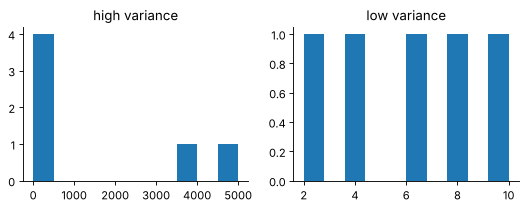

In [12]:
high_var = np.array([1, 100, 200, 300, 4000, 5000])
low_var = np.array([2, 4, 6, 8, 10])
for name, arr in [("high", high_var), ("low", low_var)]:
    print(f"{name}: mean={arr.mean():.1f} var={arr.var():.1f} std={arr.std():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 2.5))
axes[0].hist(high_var); axes[0].set_title("high variance")
axes[1].hist(low_var); axes[1].set_title("low variance")
plt.show()

<a id="reshape-transpose-and-the-dot-product"></a>

### Reshape, Transpose and the Dot Product

`reshape` changes an array's shape without changing its data (`-1` means "infer this dimension"), and `.T` swaps the axes.
Both come up constantly when shapes don't line up.

Element-wise multiplication (`a * b`) needs matching or broadcastable shapes. The **dot product** (`a @ b`, matrix
multiplication) needs the **inner** dimensions to match: `(m, n) @ (n, p)` gives `(m, p)`.

A concrete use: five days of sales for three products, multiplied by the price of each product, gives daily revenue.

In [13]:
a2 = np.array([[1, 2.0, 3.3], [4, 5, 6.5]])
print((a2.reshape(2, 3, 1) * np.arange(18).reshape(2, 3, 3)).shape, a2.T.shape)

np.random.seed(0)
mat1, mat2 = np.random.randint(10, size=(5, 3)), np.random.randint(10, size=(5, 3))
try:
    mat1 @ mat2
except ValueError:
    print("(5, 3) @ (5, 3) fails; with a transpose:", (mat1 @ mat2.T).shape)

np.random.seed(0)
sales = np.random.randint(20, size=(5, 3))
prices = np.array([10, 8, 12])
weekly = pd.DataFrame(sales, index=["Mon", "Tues", "Wed", "Thurs", "Fri"],
                      columns=["Almond butter", "Peanut butter", "Cashew butter"])
weekly["Total ($)"] = sales @ prices                 # (5, 3) @ (3,) -> (5,)
print(weekly)

(2, 3, 3) (3, 2)
(5, 3) @ (5, 3) fails; with a transpose: (5, 5)
       Almond butter  Peanut butter  Cashew butter  Total ($)
Mon               12             15              0        240
Tues               3              3              7        138
Wed                9             19             18        458
Thurs              4              6             12        232
Fri                1              6              7        142


<a id="comparisons-sorting-and-argmax"></a>

### Comparisons, Sorting and argmax

Comparisons (`>`, `==`) are element-wise and return boolean masks. `np.sort` sorts values, `np.argsort` returns the
indices that would sort them, and `np.argmax` returns the index of the largest value. That last one is exactly how
prediction probabilities become class labels later.

In [14]:
np.random.seed(0)
random_array = np.random.randint(10, size=(3, 5))
print(random_array)
print("mask > 5:\n", random_array > 5)
print("sorted rows:\n", np.sort(random_array))
print("argmax per row:", np.argmax(random_array, axis=1))

[[5 0 3 3 7]
 [9 3 5 2 4]
 [7 6 8 8 1]]
mask > 5:
 [[False False False False  True]
 [ True False False False False]
 [ True  True  True  True False]]
sorted rows:
 [[0 3 3 5 7]
 [2 3 4 5 9]
 [1 6 7 8 8]]
argmax per row: [4 0 2]


<a id="images-are-just-arrays"></a>

### Images Are Just Arrays

An image is a grid of pixels. A grayscale pixel is one number from 0 (black) to 255 (white); a colour pixel is three
numbers, one each for red, green and blue. So an image is an array with shape height × width × channels, and a batch of
images adds a leading dimension: `(N, height, width, 3)`. `matplotlib.image.imread()` loads one into an array,
which is the first step of any computer-vision pipeline.

**Watch out:** the value range depends on the file format. JPEG files load as integers 0–255 (`uint8`) with 3 channels
(red, green, blue). PNG files load as floats 0–1, often with a 4th **alpha** (transparency) channel. Check `shape` and
`dtype` before feeding images to a model.

<class 'numpy.ndarray'> (500, 500, 3) uint8 min/max: 0 255
top-left pixel (R, G, B): [254 255 253]


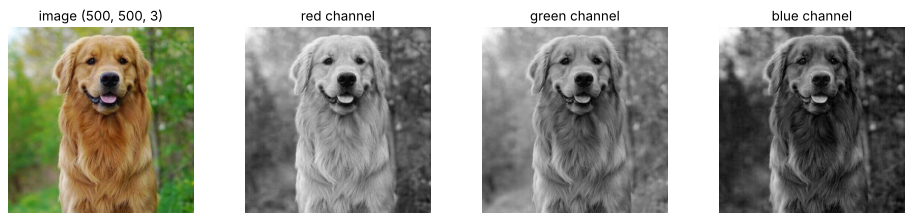

In [15]:
from matplotlib.image import imread

dog = imread(DATA / "dog-photos" / "golden-retriever.jpeg")
print(type(dog), dog.shape, dog.dtype, "min/max:", dog.min(), dog.max())
print("top-left pixel (R, G, B):", dog[0, 0])
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
axes[0].imshow(dog); axes[0].set_title(f"image {dog.shape}")
for ax, c, name in zip(axes[1:], range(3), ["red", "green", "blue"]):
    ax.imshow(dog[..., c], cmap="gray", vmin=0, vmax=255); ax.set_title(f"{name} channel")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

#### Exercise 2

Create a 3 × 4 array of random integers between 0 and 100 with `default_rng(7)`. Print the column means, the index of the
largest value in each row, and the array scaled to 0–1 per column using broadcasting: `(x - min) / (max - min)`.

#### Solution 2

*Try it yourself before running this cell.*

In [16]:
rng = np.random.default_rng(7)
arr = rng.integers(0, 100, size=(3, 4))
print(arr)
print("column means:", arr.mean(axis=0))
print("argmax per row:", arr.argmax(axis=1))
col_min, col_max = arr.min(axis=0), arr.max(axis=0)        # shapes (4,) broadcast against (3, 4)
print(((arr - col_min) / (col_max - col_min)).round(2))

[[94 62 68 89]
 [57 77 83 22]
 [ 5 30 28 87]]
column means: [52.         56.33333333 59.66666667 66.        ]
argmax per row: [0 2 3]
[[1.   0.68 0.73 1.  ]
 [0.58 1.   1.   0.  ]
 [0.   0.   0.   0.97]]


<a id="cheatsheet-numpy"></a>

### Cheatsheet: NumPy

```python
np.array(list); np.zeros(shape); np.ones(shape); np.arange(start, stop, step)
rng = np.random.default_rng(42); rng.integers(0, 10, size=(3, 3)); rng.random((2, 2))
a.shape; a.ndim; a.dtype; a.size; a[0, 1:3]; a[:, ::2]; a[a > 5]
a + b; a * b; a @ b; a.T; a.reshape(2, -1)
a.sum(axis=0); a.mean(); a.std(); a.var(); np.unique(a); np.sort(a); np.argsort(a); a.argmax(axis=1)
```

| Operation | Shape rule |
|---|---|
| element-wise `a * b` | equal, or broadcastable (compare from the right: equal or 1) |
| dot product `a @ b` | inner dimensions equal: `(m, n) @ (n, p) -> (m, p)` |

<a id="6-visualizing-data-with-matplotlib"></a>

## 6. Visualizing Data with Matplotlib

Plots are how you understand data, and how you explain it to everyone else. Matplotlib is the foundation, and pandas and
seaborn both build on it.

<a id="figures-axes-and-the-two-plotting-styles"></a>

### Figures, Axes and the Two Plotting Styles

Matplotlib has two interfaces:

- **pyplot** (`plt.plot(x, y)`) is quick and implicit, which makes it handy for a fast look.
- The **object-oriented API** (`fig, ax = plt.subplots()`, then `ax.plot(...)`) is explicit about which figure and axes
  you're drawing on. Use it for anything you'll customize or share.

A **Figure** is the whole canvas, and it holds one or more **Axes**. Each Axes is an individual plot with its own x-axis,
y-axis, title, labels, ticks and legend:

![Anatomy of a Matplotlib figure](https://matplotlib.org/stable/_images/anatomy.png)

*Anatomy of a figure. Image: [Matplotlib documentation](https://matplotlib.org/stable/users/explain/quick_start.html).*

The workflow is always the same: prepare the data, create the figure and axes, plot, customize, then save or show.

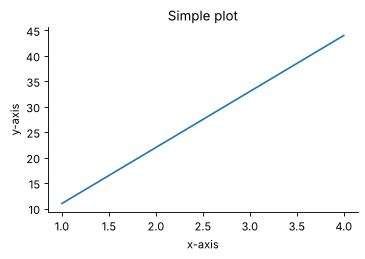

In [17]:
fig, ax = plt.subplots(figsize=(5, 3))                          # 1. figure + axes
ax.plot([1, 2, 3, 4], [11, 22, 33, 44])                         # 2. plot
ax.set(title="Simple plot", xlabel="x-axis", ylabel="y-axis")   # 3. customize
fig.savefig("sample-plot.png")                                  # 4. save
plt.show()

<a id="line-scatter-bar-and-histogram"></a>

### Line, Scatter, Bar and Histogram

Pick the plot for the question you're asking: a **line** for a trend over an ordered axis, a **scatter** for the
relationship between two numbers, a **bar** chart to compare categories (`barh` for horizontal), and a **histogram** for
the distribution of one variable.

Subplots come in two equivalent forms. You can unpack them directly with `fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2)`,
or keep the array and index it with `axes[0, 1]`.

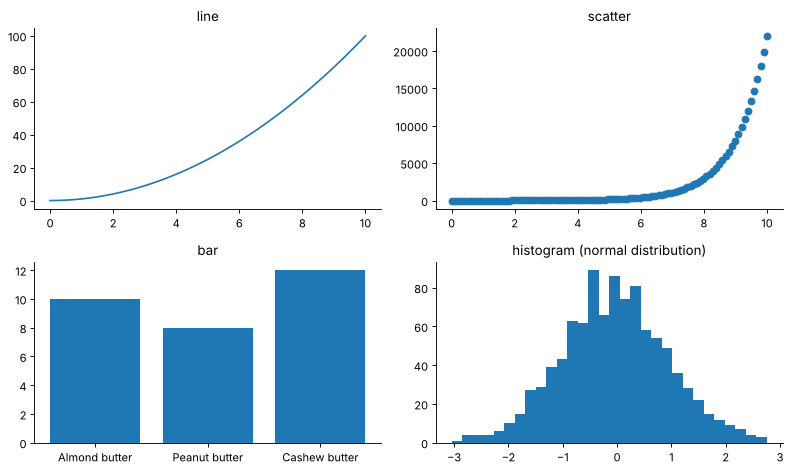

In [18]:
x = np.linspace(0, 10, 100)
prices = {"Almond butter": 10, "Peanut butter": 8, "Cashew butter": 12}

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(x, x ** 2); axes[0, 0].set_title("line")
axes[0, 1].scatter(x, np.exp(x)); axes[0, 1].set_title("scatter")
axes[1, 0].bar(list(prices), list(prices.values())); axes[1, 0].set_title("bar")
axes[1, 1].hist(np.random.randn(1000), bins=30); axes[1, 1].set_title("histogram (normal distribution)")
plt.tight_layout(); plt.show()

<a id="plotting-straight-from-pandas"></a>

### Plotting Straight from pandas

DataFrames and Series have a `.plot()` method (`kind="line" | "scatter" | "bar" | "hist"`) built on Matplotlib. You can
mix the two styles by passing `ax=` to a pandas plot, so pandas draws on an Axes you control.

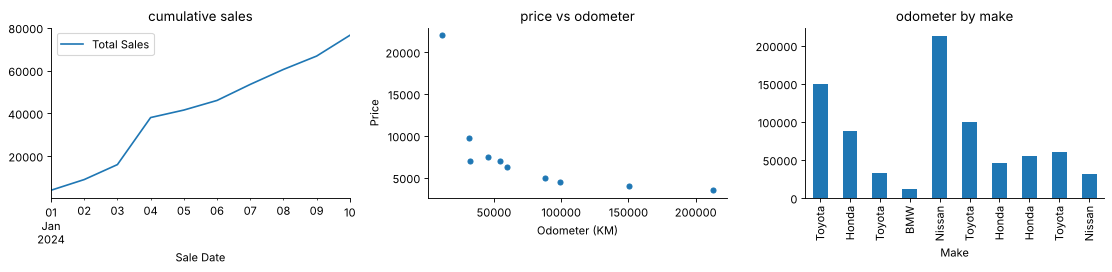

In [19]:
car_sales = pd.read_csv(DATA / "car-sales.csv")
car_sales["Price"] = pd.to_numeric(car_sales["Price"].str.replace(r"[$,]", "", regex=True))
car_sales["Sale Date"] = pd.date_range("2024-01-01", periods=len(car_sales))
car_sales["Total Sales"] = car_sales["Price"].cumsum()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
car_sales.plot(x="Sale Date", y="Total Sales", ax=axes[0], title="cumulative sales")
car_sales.plot(kind="scatter", x="Odometer (KM)", y="Price", ax=axes[1], title="price vs odometer")
car_sales.plot(kind="bar", x="Make", y="Odometer (KM)", ax=axes[2], title="odometer by make", legend=False)
plt.tight_layout(); plt.show()

A more realistic example uses the heart-disease data. It plots patients over 50, age against cholesterol and against
maximum heart rate, coloured by diagnosis, with a dashed line at the mean:

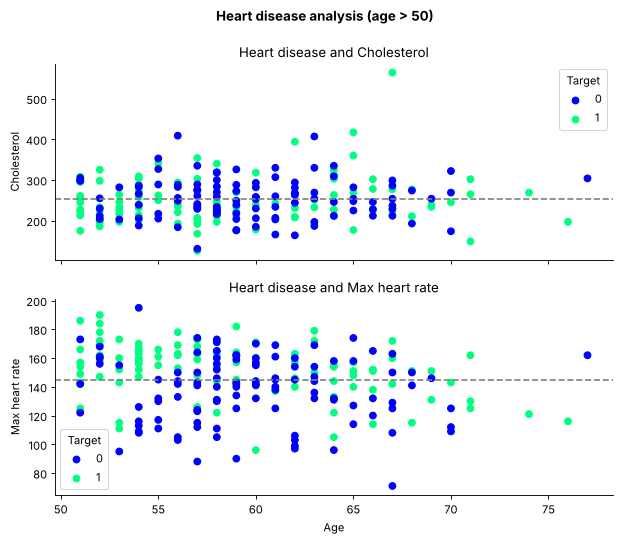

In [20]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
over_50 = heart_disease[heart_disease["age"] > 50]

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for ax, col, title in [(ax0, "chol", "Cholesterol"), (ax1, "thalach", "Max heart rate")]:
    sc = ax.scatter(over_50["age"], over_50[col], c=over_50["target"], cmap="winter")
    ax.axhline(over_50[col].mean(), linestyle="--", color="grey")     # mean line
    ax.set(title=f"Heart disease and {title}", ylabel=title)
    ax.legend(*sc.legend_elements(), title="Target")
ax1.set_xlabel("Age")
fig.suptitle("Heart disease analysis (age > 50)", fontweight="bold")
plt.show()

<a id="styling-and-saving"></a>

### Styling and Saving

Styles change the whole look at once (`plt.style.available` lists them). Use `plt.style.context(...)` to apply one only
inside a `with` block. Axis limits come from `ax.set(xlim=..., ylim=...)` or `sharex=True`, colours from `cmap=`, and
reference lines from `ax.axhline()`. Save with `fig.savefig("name.png", dpi=..., bbox_inches="tight")`: use PNG for slides
and SVG or PDF for documents.

**Watch out:** the style called `"seaborn"` was renamed `"seaborn-v0_8"` in Matplotlib 3.6, so older code using the old
name fails.

['seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark'] ...


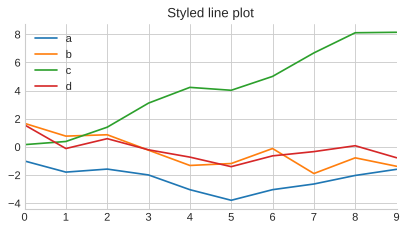

In [21]:
print([s for s in plt.style.available if s.startswith("seaborn")][:4], "...")
with plt.style.context("seaborn-v0_8-whitegrid"):
    fig, ax = plt.subplots(figsize=(6, 3))
    data = np.random.randn(10, 4).cumsum(axis=0)
    for i, label in enumerate("abcd"):
        ax.plot(data[:, i], label=label)
    ax.set(title="Styled line plot", xlim=(0, 9)); ax.legend(loc="upper left")
    plt.show()

#### Exercise 3

From `heart-disease.csv`, make a 1 × 2 figure: a histogram of `age`, and a bar chart of the count of each `cp` (chest-pain
type) split by `target`, using `pd.crosstab(...).plot(kind="bar", ax=...)`. Give both titles and save the figure.

#### Solution 3

*Try it yourself before running this cell.*

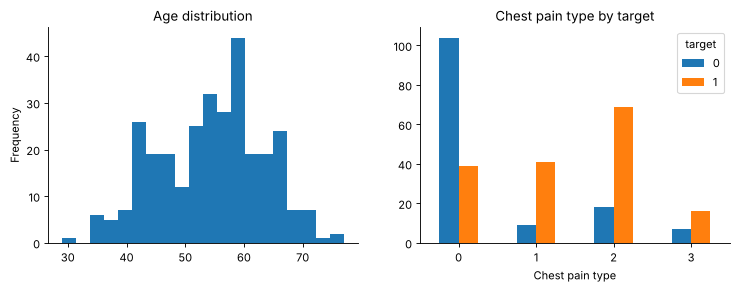

In [22]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
heart_disease["age"].plot.hist(bins=20, ax=axes[0], title="Age distribution")
pd.crosstab(heart_disease["cp"], heart_disease["target"]).plot(kind="bar", ax=axes[1],
                                                                title="Chest pain type by target")
axes[1].set_xlabel("Chest pain type"); axes[1].tick_params(axis="x", rotation=0)
fig.savefig("heart-disease-overview.png", bbox_inches="tight")
plt.show()

<a id="cheatsheet-matplotlib"></a>

### Cheatsheet: Matplotlib

```python
fig, ax = plt.subplots(figsize=(10, 6)); fig, axes = plt.subplots(2, 2)      # axes[0, 1]
ax.plot(x, y); ax.scatter(x, y, c=labels, cmap="winter"); ax.bar(names, values); ax.hist(data, bins=30)
ax.set(title="...", xlabel="...", ylabel="...", xlim=(0, 10)); ax.legend(); ax.axhline(y.mean(), linestyle="--")
df.plot(kind="scatter", x="a", y="b", ax=ax); df["col"].plot.hist()
plt.style.use("seaborn-v0_8"); fig.savefig("plot.png", bbox_inches="tight")
```

| Question | Plot |
|---|---|
| trend over time | line |
| relationship between two numbers | scatter |
| compare categories | bar / barh |
| distribution of one variable | histogram |

<a id="7-building-models-with-scikit-learn"></a>

## 7. Building Models with scikit-learn

scikit-learn gives every model the same interface (`fit`, `predict`, `score`), plus tools for preparing data, evaluating
models, tuning hyperparameters and saving the result. Learn the pattern once and it transfers to dozens of algorithms. In
scikit-learn terms, a model is called an **estimator**.

<a id="the-workflow-in-one-cell"></a>

### The Workflow in One Cell

```mermaid
flowchart LR
    A[Get data ready: X, y, split] --> B[Choose an estimator] --> C["fit(X_train, y_train)"]
    C --> D["predict(X_test)"] --> E[Evaluate] --> F[Improve: tune hyperparameters] --> G[Save the model]
    F -.re-fit.-> C
```

Everything in this section expands on one of those boxes. Here is the whole loop end to end on the heart-disease data: split
features `X` from labels `y`, fit a random forest, score it, try a few values of one hyperparameter, then save and reload
the model.

In [23]:
# The whole scikit-learn workflow in one cell (heart disease classification).
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X = heart_disease.drop(columns="target")      # features
y = heart_disease["target"]                   # labels (1 = heart disease)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
print("Test accuracy:", round(clf.score(X_test, y_test), 3))

# Improve: try a few values of one hyperparameter.
for n in [10, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    print(f"n_estimators={n:>3}: {model.score(X_test, y_test):.3f}")

# Save and load.
with open("random-forest-model-1.pkl", "wb") as f:
    pickle.dump(clf, f)
with open("random-forest-model-1.pkl", "rb") as f:
    loaded = pickle.load(f)
print("Loaded model accuracy:", round(loaded.score(X_test, y_test), 3))

Test accuracy: 0.836
n_estimators= 10: 0.852
n_estimators= 50: 0.869


n_estimators=100: 0.836


n_estimators=200: 0.836
Loaded model accuracy: 0.836


<a id="getting-data-ready"></a>

### Getting Data Ready

Three jobs come before any modelling: **split** the data into features and labels (and train/test), **convert** non-numeric
values to numbers, and **handle missing values**. In short: clean, transform, reduce.

Text columns break models immediately with *could not convert string to float*. **One-hot encoding** turns each category
into its own 0/1 column. In scikit-learn, you do this with `OneHotEncoder` inside a `ColumnTransformer`, using
`remainder="passthrough"` to keep the other columns. Note that `Doors` is stored as a number but is really a category.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

car_sales = pd.read_csv(DATA / "car-sales-extended.csv")
X, y = car_sales.drop(columns="Price"), car_sales["Price"]

try:
    RandomForestRegressor().fit(X, y)
except ValueError as err:
    print("Fails on text:", str(err).splitlines()[0])

categorical = ["Make", "Colour", "Doors"]          # Doors is numeric but categorical in meaning
transformer = ColumnTransformer([("one_hot", OneHotEncoder(handle_unknown="ignore"), categorical)],
                                remainder="passthrough")
X_encoded = transformer.fit_transform(X)
print("Encoded shape:", X_encoded.shape)
print(pd.get_dummies(X[["Make", "Colour"]]).head(3))

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(random_state=42).fit(X_train, y_train)
print("R^2:", round(model.score(X_test, y_test), 3))

Fails on text: could not convert string to float: 'Honda'
Encoded shape: (1000, 13)
   Make_BMW  Make_Honda  Make_Nissan  Make_Toyota  Colour_Black  Colour_Blue  \
0     False        True        False        False         False        False   
1      True       False        False        False         False         True   
2     False        True        False        False         False        False   

   Colour_Green  Colour_Red  Colour_White  
0         False       False          True  
1         False       False         False  
2         False       False          True  


R^2: 0.294


**Watch out:** fitting the encoder on all of `X` before splitting lets the test set influence preprocessing. For one-hot
encoding the effect is tiny, but the same habit with imputers and scalers is real leakage. The
[pipeline version](#pipelines-preprocessing-and-model-as-one-object) below fits preprocessing on training data only.

For **missing values** you can either fill them (*imputation*) or drop rows. Filling is never perfect, because you are
inventing data, so pick strategies that make sense per column: a placeholder like `"missing"` for categories, the most
common value or a sensible default for discrete columns, the mean or median for numbers. Always drop rows where the
**target** is missing, since an example without a label teaches nothing.

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

car_sales_missing = pd.read_csv(DATA / "car-sales-extended-missing-data.csv")
print("Missing:\n", car_sales_missing.isna().sum(), "\n")

car_sales_missing = car_sales_missing.dropna(subset=["Price"])      # no label, no learning
X, y = car_sales_missing.drop(columns="Price"), car_sales_missing["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = ColumnTransformer([
    ("cat", SimpleImputer(strategy="constant", fill_value="missing"), ["Make", "Colour"]),
    ("door", SimpleImputer(strategy="constant", fill_value=4), ["Doors"]),
    ("num", SimpleImputer(strategy="mean"), ["Odometer (KM)"]),
])
X_train_filled = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)   # fit on train...
X_test_filled = pd.DataFrame(imputer.transform(X_test), columns=X.columns)         # ...reuse on test
print("Missing after imputation:", int(X_train_filled.isna().sum().sum()), int(X_test_filled.isna().sum().sum()))

Missing:
 Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64 

Missing after imputation: 0 0


Cleaning, encoding, scaling and feature reduction go much deeper in the
[Data Preparation reference](https://github.com/rokon-uddin/data-preparation-reference).

<a id="choosing-an-estimator"></a>

### Choosing an Estimator

scikit-learn publishes a [flowchart for choosing an estimator](https://scikit-learn.org/stable/machine_learning_map.html)
based on the problem type and dataset size. In practice I start with a simple linear model as a baseline and then try a
tree ensemble.

For regression on California housing (20,640 districts, target = median house value in $100,000s), `Ridge` is the linear
baseline and `RandomForestRegressor` is an **ensemble** that averages many decision trees. The forest wins comfortably.

**Watch out:** many tutorials use `load_boston()`. It was removed in scikit-learn 1.2 because one of its features was
derived from the proportion of Black residents. Use `fetch_california_housing()` instead.

In [26]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True)
housing_df = housing.frame                                   # features + "MedHouseVal" target
print(housing_df.shape)

X, y = housing_df.drop(columns="MedHouseVal"), housing_df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for model in [Ridge(), RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)]:
    model.fit(X_train, y_train)
    print(f"{type(model).__name__:24s} R^2 = {model.score(X_test, y_test):.3f}")

(20640, 9)
Ridge                    R^2 = 0.576


RandomForestRegressor    R^2 = 0.805


For classification on heart disease, the flowchart suggests `LinearSVC` first. On this small dataset the linear model
actually edges out the random forest on a single split, which is a good reminder to test rather than assume.

In [27]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for model in [LinearSVC(max_iter=10_000, random_state=42), RandomForestClassifier(random_state=42)]:
    model.fit(X_train, y_train)
    print(f"{type(model).__name__:24s} accuracy = {model.score(X_test, y_test):.3f}")

LinearSVC                accuracy = 0.869
RandomForestClassifier   accuracy = 0.836


<a id="predictions-and-probabilities"></a>

### Predictions and Probabilities

`fit(X, y)` is where the model learns. `predict(X)` returns labels (or numbers, for regression), and new data must have
**the same features in the same format** as the training data. `predict_proba(X)` returns a probability per class, and
`predict` picks the most probable one, which means a 0.5 threshold for binary problems. Probabilities are what you need
for ROC curves and for adjusting the threshold to the cost of mistakes.

In [28]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print("predict:      ", clf.predict(X_test[:5]))
print("predict_proba:\n", clf.predict_proba(X_test[:5]).round(2))
print("same as accuracy_score:", clf.score(X_test, y_test) == accuracy_score(y_test, clf.predict(X_test)))

housing = fetch_california_housing(as_frame=True)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)
reg = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(Xh_train, yh_train)
print("regression predictions:", reg.predict(Xh_test[:5]).round(2), "| truth:", yh_test[:5].values)
print("MAE:", round(mean_absolute_error(yh_test, reg.predict(Xh_test)), 3))

predict:       [0 1 1 0 1]
predict_proba:
 [[0.95 0.05]
 [0.38 0.62]
 [0.45 0.55]
 [0.86 0.14]
 [0.21 0.79]]
same as accuracy_score: True


regression predictions: [0.51 0.75 4.96 2.5  2.25] | truth: [0.477   0.458   5.00001 2.186   2.78   ]
MAE: 0.328


<a id="evaluating-a-model-and-cross-validation"></a>

### Evaluating a Model and Cross-Validation

There are three ways to evaluate in scikit-learn:

1. The estimator's built-in `score()`, which is mean accuracy for classifiers and R² for regressors.
2. The `scoring` parameter of tools like `cross_val_score` and `GridSearchCV`.
3. Metric functions in `sklearn.metrics`, called on true and predicted values.

A single train/test split can be lucky or unlucky. **Cross-validation** trains and evaluates on *k* different splits
(5 by default) and averages the scores, giving a far more trustworthy estimate.

```mermaid
flowchart LR
    subgraph "5-fold cross-validation"
        F1["Fold 1: test | train train train train"]
        F2["Fold 2: train | test | train train train"]
        F3["..."]
        F5["Fold 5: train train train train | test"]
    end
    F1 & F2 & F3 & F5 --> AVG[Average the 5 scores]
```

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

print("Single split score:", round(clf.score(X_test, y_test), 3))
cv_scores = cross_val_score(RandomForestClassifier(random_state=42), X, y, cv=5)
print("5-fold CV scores:  ", cv_scores.round(3), "-> mean", round(cv_scores.mean(), 3))

Single split score: 0.836


5-fold CV scores:   [0.82  0.885 0.836 0.85  0.8  ] -> mean 0.838


<a id="classification-metrics-accuracy-roc-and-auc"></a>

### Classification Metrics: Accuracy, ROC and AUC

**Accuracy** is correct predictions divided by all predictions. It's fine when the classes are balanced, but misleading
when they aren't.

The **ROC curve** plots the true-positive rate against the false-positive rate at every probability threshold. A perfect
model hugs the top-left corner, and random guessing follows the diagonal. **AUC**, the area under that curve, summarizes it
in one number: 1.0 is perfect, 0.5 is a coin flip.

**Watch out:** `plot_roc_curve` was removed in scikit-learn 1.2. Use `RocCurveDisplay.from_estimator(...)` or
`RocCurveDisplay.from_predictions(...)`.

Cross-validated accuracy: 83.82%
AUC: 0.92


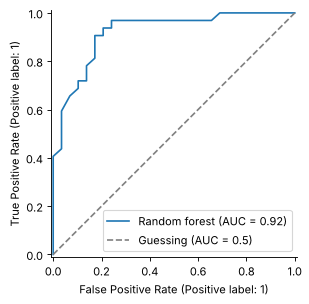

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import train_test_split, cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

cv_acc = cross_val_score(clf, X, y, cv=5, scoring="accuracy")
print(f"Cross-validated accuracy: {cv_acc.mean() * 100:.2f}%")

y_probs = clf.predict_proba(X_test)[:, 1]                  # probability of the positive class
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
print("AUC:", round(roc_auc_score(y_test, y_probs), 3))

fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, y_probs, ax=ax, name="Random forest")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Guessing (AUC = 0.5)")
ax.legend(); plt.show()

<a id="classification-metrics-the-confusion-matrix"></a>

### Classification Metrics: The Confusion Matrix

A **confusion matrix** shows exactly where the model gets confused. In scikit-learn, rows are the **true** labels and
columns the **predicted** labels, so a binary matrix reads `[[TN, FP], [FN, TP]]`. A seaborn heatmap or
`ConfusionMatrixDisplay` makes it readable at a glance (`plot_confusion_matrix` was removed in 1.2).

[[24  5]
 [ 5 27]]
Predicted   0   1
Actual           
0          24   5
1           5  27


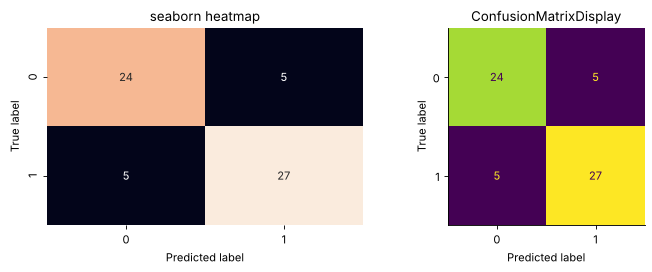

In [31]:
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_preds = RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)

print(confusion_matrix(y_test, y_preds))
print(pd.crosstab(y_test, y_preds, rownames=["Actual"], colnames=["Predicted"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.heatmap(confusion_matrix(y_test, y_preds), annot=True, cbar=False, ax=axes[0])
axes[0].set(xlabel="Predicted label", ylabel="True label", title="seaborn heatmap")
ConfusionMatrixDisplay.from_predictions(y_test, y_preds, ax=axes[1], colorbar=False)
axes[1].set_title("ConfusionMatrixDisplay")
plt.tight_layout(); plt.show()

<a id="classification-metrics-precision-recall-and-f1"></a>

### Classification Metrics: Precision, Recall and F1

`classification_report` shows each class's **precision** (of the positives you predicted, how many were right), **recall**
(of the actual positives, how many you found), **F1** (their harmonic mean) and **support** (number of samples). The
*macro* average treats classes equally, and the *weighted* average weights them by support.

| Metric | Formula | Use when |
|---|---|---|
| Accuracy | (TP + TN) / all | classes are balanced |
| Precision | TP / (TP + FP) | false positives are costly (spam filters) |
| Recall | TP / (TP + FN) | false negatives are costly (disease screening) |
| F1 | 2·P·R / (P + R) | you need one balanced number |

The second half of the cell shows why accuracy alone is dangerous. With 1 positive in 10,000, a model that always says
"negative" scores 99.99% accuracy and finds nothing.

In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_preds = RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)
print(classification_report(y_test, y_preds))

# The imbalanced-data trap: 1 positive in 10,000, model always predicts 0.
disease_true = np.zeros(10_000); disease_true[0] = 1
disease_preds = np.zeros(10_000)
print(pd.DataFrame(classification_report(disease_true, disease_preds, output_dict=True, zero_division=0)).round(4))

              precision    recall  f1-score   support

           0       0.83      0.83      0.83        29
           1       0.84      0.84      0.84        32

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61

                 0.0  1.0  accuracy  macro avg  weighted avg
precision     0.9999  0.0    0.9999        0.5        0.9998
recall        1.0000  0.0    0.9999        0.5        0.9999
f1-score      0.9999  0.0    0.9999        0.5        0.9999
support    9999.0000  1.0    0.9999    10000.0    10000.0000


<a id="regression-metrics-r-mae-mse-and-rmse"></a>

### Regression Metrics: R², MAE, MSE and RMSE

- **R²** is the share of the target's variation the model explains. Predicting the mean everywhere scores 0, and perfect
  predictions score 1.
- **MAE** is the average absolute error, in the target's units: "on average we're off by X".
- **MSE** is the average squared error. Squaring punishes large mistakes more, which suits problems where being off by 10 is
  more than twice as bad as being off by 5.
- **RMSE** is the square root of MSE, which puts it back in the target's units (`root_mean_squared_error`, scikit-learn ≥ 1.4).

In [33]:
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)
y_preds = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(X_train, y_train).predict(X_test)

print("R^2 of always predicting the mean:", r2_score(y_test, np.full(len(y_test), y_test.mean())))
print(f"R^2  {r2_score(y_test, y_preds):.3f}")
print(f"MAE  {mean_absolute_error(y_test, y_preds):.3f}  (manual: {np.abs(y_preds - y_test).mean():.3f})")
print(f"MSE  {mean_squared_error(y_test, y_preds):.3f}  (manual: {np.square(y_preds - y_test).mean():.3f})")
print(f"RMSE {root_mean_squared_error(y_test, y_preds):.3f}")

R^2 of always predicting the mean: 0.0
R^2  0.805
MAE  0.328  (manual: 0.328)
MSE  0.256  (manual: 0.256)
RMSE 0.506


<a id="the-scoring-parameter"></a>

### The scoring Parameter

`cross_val_score(model, X, y, cv=5, scoring="precision")` cross-validates any metric. Error metrics are **negated**
(`"neg_mean_absolute_error"`) because scikit-learn always maximizes scores, so flip the sign when you report them.

In [34]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
clf = RandomForestClassifier(random_state=42)
for metric in ["accuracy", "precision", "recall", "f1"]:
    print(f"{metric:9s} {cross_val_score(clf, X, y, cv=5, scoring=metric).mean():.3f}")

housing = fetch_california_housing(as_frame=True)
sample = housing.frame.sample(5000, random_state=42)               # subset keeps this cell fast
reg = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42)
mae = cross_val_score(reg, sample.drop(columns="MedHouseVal"), sample["MedHouseVal"],
                      cv=3, scoring="neg_mean_absolute_error")
print("Regression MAE (sign flipped):", round(-mae.mean(), 3))

accuracy  0.838


precision 0.847


recall    0.861


f1        0.853


Regression MAE (sign flipped): 0.391


<a id="tuning-hyperparameters-by-hand"></a>

### Tuning Hyperparameters by Hand

First predictions are rarely final. You can improve from the **data** side (more data, better features) or the **model**
side (a different model, better hyperparameters). `model.get_params()` lists every hyperparameter. For random forests the
usual suspects are `n_estimators`, `max_depth`, `max_features`, `min_samples_split` and `min_samples_leaf`.

Tuning by hand uses three sets: train on the training set, compare settings on the **validation** set, and report once on
the **test** set. A small `evaluate_preds` helper keeps the comparison consistent.

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_preds(y_true, y_preds):
    """Classification metrics in one dictionary (handy for comparing experiments)."""
    return {"accuracy": round(accuracy_score(y_true, y_preds), 2), "precision": round(precision_score(y_true, y_preds), 2),
            "recall": round(recall_score(y_true, y_preds), 2), "f1": round(f1_score(y_true, y_preds), 2)}

heart_disease = pd.read_csv(DATA / "heart-disease.csv").sample(frac=1, random_state=42)   # shuffle
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
train_end, valid_end = round(0.7 * len(X)), round(0.85 * len(X))
X_train, y_train = X[:train_end], y[:train_end]
X_valid, y_valid = X[train_end:valid_end], y[train_end:valid_end]
X_test, y_test = X[valid_end:], y[valid_end:]
print("train/valid/test:", len(X_train), len(X_valid), len(X_test))

baseline = RandomForestClassifier(random_state=42).fit(X_train, y_train)
print("baseline (valid):", evaluate_preds(y_valid, baseline.predict(X_valid)))
tuned = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42).fit(X_train, y_train)
print("max_depth=10 (valid):", evaluate_preds(y_valid, tuned.predict(X_valid)))

train/valid/test: 212 46 45
baseline (valid): {'accuracy': 0.83, 'precision': 0.85, 'recall': 0.85, 'f1': 0.85}


max_depth=10 (valid): {'accuracy': 0.8, 'precision': 0.81, 'recall': 0.85, 'f1': 0.83}


<a id="randomizedsearchcv-and-gridsearchcv"></a>

### RandomizedSearchCV and GridSearchCV

- **`RandomizedSearchCV`** samples `n_iter` random combinations from a grid and cross-validates each. It's fast and good
  for wide searches.
- **`GridSearchCV`** tries **every** combination. It's thorough but the cost multiplies quickly (4 × 4 × 2 × 3 × 3 = 288
  combinations × 5 folds = 1,440 fits), so narrow the grid around the best randomized results first.

Both refit the best model on all the training data (`refit=True`), which you can then use as `best_estimator_`.

**Watch out:** `max_features="auto"` no longer exists. Use `"sqrt"`, `"log2"`, a float fraction or `None`.

Randomized best: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10}


Grid best:       {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


           baseline  random search  grid search
accuracy      0.836          0.869        0.869
precision     0.844          0.853        0.853
recall        0.844          0.906        0.906
f1            0.844          0.879        0.879


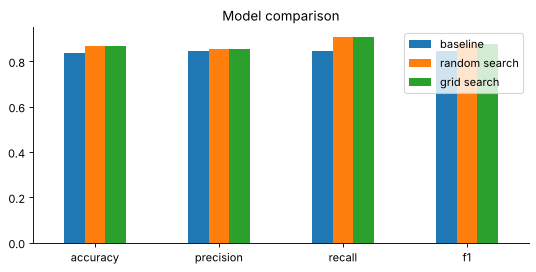

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

grid = {"n_estimators": [10, 100, 200, 500], "max_depth": [None, 5, 10, 20],
        "max_features": ["sqrt", "log2"], "min_samples_split": [2, 4, 6], "min_samples_leaf": [1, 2, 4]}
rs_clf = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), grid, n_iter=10, cv=5,
                            random_state=42).fit(X_train, y_train)
print("Randomized best:", rs_clf.best_params_)

grid_2 = {"n_estimators": [100, 200], "max_depth": [None, 10], "max_features": ["sqrt"],
          "min_samples_split": [2, 6], "min_samples_leaf": [1, 2]}
gs_clf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), grid_2, cv=5).fit(X_train, y_train)
print("Grid best:      ", gs_clf.best_params_)

results = {}
for name, model in [("baseline", RandomForestClassifier(random_state=42).fit(X_train, y_train)),
                    ("random search", rs_clf), ("grid search", gs_clf)]:
    p = model.predict(X_test)
    results[name] = {"accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                     "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)}
compare = pd.DataFrame(results).round(3)
print(compare)
compare.plot.bar(figsize=(8, 3.5), rot=0, title="Model comparison"); plt.show()

<a id="saving-and-loading-models"></a>

### Saving and Loading Models

`pickle` can save any Python object. `joblib` is more efficient for objects that hold large NumPy arrays, which describes
most scikit-learn models. Two rules: only load files you trust (loading executes code), and load with the same
scikit-learn version you saved with.

In [37]:
from joblib import dump, load
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
clf = RandomForestClassifier(random_state=42).fit(X_train, y_train)

dump(clf, "random-forest-model.joblib")
loaded = load("random-forest-model.joblib")
print("Same predictions after reload:", (loaded.predict(X_test) == clf.predict(X_test)).all())

Same predictions after reload: True


<a id="pipelines-preprocessing-and-model-as-one-object"></a>

### Pipelines: Preprocessing and Model as One Object

A `Pipeline` chains preprocessing and the model, so imputing, encoding and fitting happen in one `fit` call, and new data
goes through identical steps in `predict`. That removes a whole class of train/serve mismatch bugs. Hyperparameter search
works on the whole pipeline. Parameter names join the step and the parameter with a double underscore, for example
`"model__max_depth"` or `"preprocessor__num__imputer__strategy"`.

```mermaid
flowchart LR
    X[Raw X] --> CT
    subgraph CT[ColumnTransformer]
        C1["Make, Colour: impute 'missing' → one-hot"]
        C2["Doors: impute 4 → one-hot"]
        C3["Odometer: impute mean"]
    end
    CT --> M[RandomForestRegressor] --> P[Predictions]
```

The car-sales data is synthetic and noisy, so an R² around 0.2–0.3 is expected. The point here is the structure.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

data = pd.read_csv(DATA / "car-sales-extended-missing-data.csv").dropna(subset=["Price"])
X, y = data.drop(columns="Price"), data["Price"]

categorical = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
door = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=4)),
                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])
numeric = Pipeline([("imputer", SimpleImputer(strategy="mean"))])
preprocessor = ColumnTransformer([("cat", categorical, ["Make", "Colour"]),
                                  ("door", door, ["Doors"]),
                                  ("num", numeric, ["Odometer (KM)"])])
model = Pipeline([("preprocessor", preprocessor), ("model", RandomForestRegressor(random_state=42))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
print("Pipeline R^2:", round(model.score(X_test, y_test), 3))

grid = {"preprocessor__num__imputer__strategy": ["mean", "median"],
        "model__n_estimators": [100, 500], "model__max_depth": [None, 5], "model__min_samples_split": [2, 4]}
gs_model = GridSearchCV(model, grid, cv=5).fit(X_train, y_train)
print("Best:", gs_model.best_params_)
print("Tuned pipeline R^2:", round(gs_model.score(X_test, y_test), 3))

Pipeline R^2: 0.212


Best: {'model__max_depth': 5, 'model__min_samples_split': 4, 'model__n_estimators': 500, 'preprocessor__num__imputer__strategy': 'mean'}
Tuned pipeline R^2: 0.336


#### Exercise 4

Build a heart-disease pipeline that scales features with `StandardScaler` and fits `LogisticRegression`. Tune `C` over
`np.logspace(-3, 3, 7)` with `GridSearchCV(cv=5)`, then print the best `C`, the test accuracy and the classification
report.

#### Solution 4

*Try it yourself before running this cell.*

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
search = GridSearchCV(pipe, {"logisticregression__C": np.logspace(-3, 3, 7)}, cv=5).fit(X_train, y_train)
print("Best C:", search.best_params_["logisticregression__C"])
print("Test accuracy:", round(search.score(X_test, y_test), 3))
print(classification_report(y_test, search.predict(X_test)))

Best C: 1.0
Test accuracy: 0.852
              precision    recall  f1-score   support

           0       0.83      0.86      0.85        29
           1       0.87      0.84      0.86        32

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



<a id="cheatsheet-scikit-learn"></a>

### Cheatsheet: scikit-learn

```python
X, y = df.drop(columns="target"), df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train); model.predict(X_test); model.predict_proba(X_test); model.score(X_test, y_test)
cross_val_score(model, X, y, cv=5, scoring="accuracy")              # "f1", "neg_mean_absolute_error", ...
RocCurveDisplay.from_estimator(model, X_test, y_test); ConfusionMatrixDisplay.from_predictions(y_test, preds)
classification_report(y_test, preds); r2_score; mean_absolute_error; root_mean_squared_error
RandomizedSearchCV(model, grid, n_iter=20, cv=5); GridSearchCV(model, grid, cv=5); .best_params_; .best_estimator_
Pipeline([("pre", ColumnTransformer([...])), ("model", model)])   # grid keys: "model__max_depth"
dump(model, "model.joblib"); model = load("model.joblib")
```

| Default `score()` | Classifier | Regressor |
|---|---|---|
| metric | mean accuracy | R² |

| Removed API | Replacement |
|---|---|
| `load_boston` | `fetch_california_housing` |
| `plot_roc_curve`, `plot_confusion_matrix` | `RocCurveDisplay`, `ConfusionMatrixDisplay` |
| `max_features="auto"` | `"sqrt"`, `1.0` |